<div style='background-color:#EEF4F7; border-left:4px solid #6F8996; border-radius:6px; padding:14px 18px; color:#243038;'>

<h1 style="color:#243038; margin:0.2em 0;">Homework 10 - The Second Half of CRISP-DM</h1>
<p style="color:#243038; margin:0.4em 0;"><strong>LTAT.02.002 Introduction to Data Science - Autumn 2026</strong></p>
<p style="color:#243038; margin:0.4em 0;"><strong>Deadline: November 30th, 2026 at noon (12:00 Europe/Tallinn time)</strong></p>

</div>

Note! This homework is submitted as groups. One group member submits on behalf of the whole team.

Not every question fits every project. If a question does not apply to yours, first adapt it to your project, and then answer it.

Most questions have an empty code cell above the answer box. Use it if code, a table or a plot helps your answer, and leave it empty if it does not - for most questions a written answer on its own is enough. Where a question asks you to show the data or a graph, use the cell.

In the previous project homework (HW7) you worked out what your project is about and what is in your data. This one takes you through the rest of CRISP-DM: preparing the data, applying a method, judging the result, and getting it ready for other people to see.

**Your project does not have to be finished by the deadline of this homework.** It has to be finished by the poster deadline, one week later. The point of the questions below is to guide and help you finish your project on time.

Where this homework sits in the process:

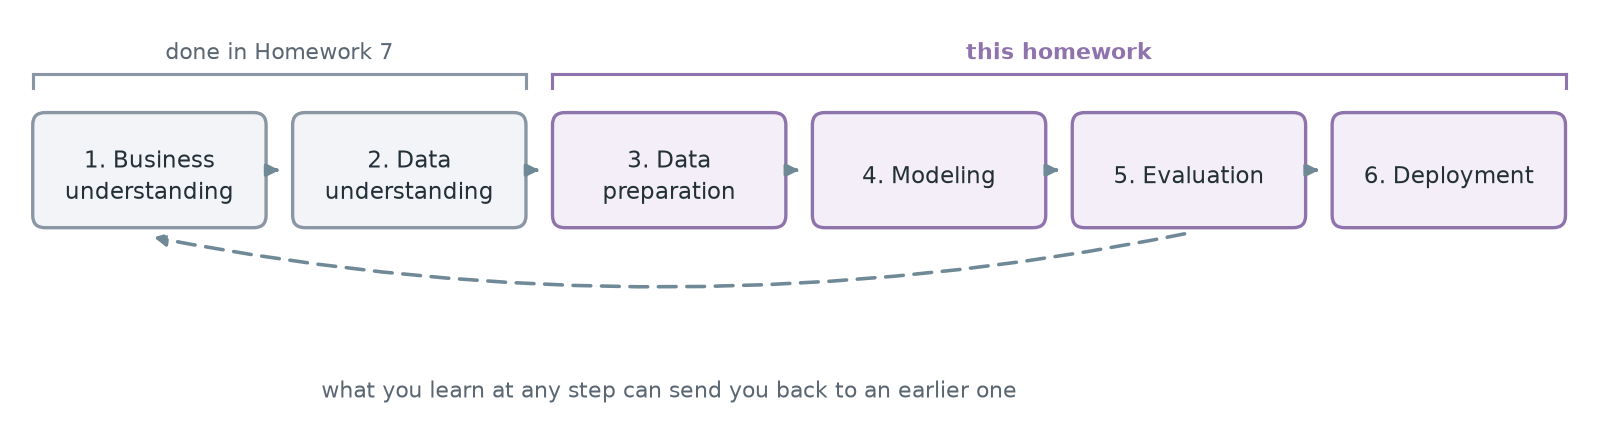

**Group ID and topic** — D3, Do wealthier Estonian municipalities have better public services?

**Team members** — Rene Miller, Arthur Klettenberg and Oliver Proos

**Repository** — https://github.com/arts05/IDS-26-group-4

<div style='background-color:#F3EEF8; border-top:1px solid #D8CCE5; border-left:4px solid #8F73AC; border-radius:6px; padding:10px 16px; margin-top:24px; color:#243038;'>

<h1 style="color:#243038; margin:0.2em 0;">1. Data preparation (0.5 points)</h1>

</div>

This is **step 3** of CRISP-DM. The aim is to get from the raw data to a table you can actually work with, and to be able to say exactly what you changed and why. Someone reading your repository later should be able to repeat every one of those steps.

**a. Show the prepared data.**

Show the table your analysis runs on - the one you ended up with after cleaning, not the raw file you started from. Print its shape, the column names and the first few rows.

The rest of this task asks how you got from the raw data to this, so it helps to have it in front of you first.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.vq import kmeans2
from scipy.spatial.distance import cdist

data_dir = Path(".")
# This sheet has several header rows. The service codes are on Excel row 8.
raw = pd.read_excel(data_dir / "Teenustasemed2024.xlsx", sheet_name="Teenustase", header=None)

service_codes = {
    "10-0": "General governance",
    "10-2": "Open governance",
    "11-1": "Pre-school education",
    "11-2": "Basic education",
    "11-3": "Youth work",
    "12-1": "Planning, construction and energy",
    "12-2": "Water management",
    "12-3": "Waste management",
    "13": "Mobility",
    "14-1": "Adult social care",
    "14-2": "Child welfare",
    "15-1": "Culture",
    "15-2": "Sport",
    "16-1": "Public health and safety",
    "16-2": "Crisis preparedness",
    "17": "Environment and climate",
    "18": "Accessibility",
    "19": "Business environment"
}

def normalize_code(value):
    if pd.isna(value):
        return None
    
    if isinstance(value, float) and value.is_integer():
        return str(int(value))
    
    return str(value).strip()


header = raw.iloc[7].map(normalize_code)
service_columns = list(service_codes.values())
positions = [header[header.eq(code)].index[0] for code in service_codes]

# Excel rows 9–87 contain the 79 municipalities.
services = raw.iloc[8:87, [0, 1, *positions]].copy().reset_index(drop=True)
services.columns = ["municipality", "ehak", *service_columns]
services["ehak"] = services["ehak"].astype(int).astype(str).str.zfill(4)
services[service_columns] = services[service_columns].apply(pd.to_numeric, errors="coerce")

# Pandas skips missing scores when calculating the mean.
services["public_service_mean"] = services[service_columns].mean(axis=1)
services["join_name"] = services["municipality"].str.strip().str.casefold()

ua08 = pd.read_csv(data_dir / "UA08_20261126-142152.csv", skiprows=2, encoding="utf-8-sig")
location = "Place of residence"
income_type = "Total work-related income"

# UA08 prefixes municipality names with two dots. Country and county totals lack them.
is_municipality = ua08[location].str.startswith("..")
municipal_income = ua08.loc[ua08["Year"].eq(2024) & is_municipality].copy()

# Match the English export to the names in the Estonian workbook.
municipal_income["join_name"] = (
    municipal_income[location].str[2:].str.strip().str.casefold()
    .str.replace(r" rural municipality$", " vald", regex=True)
    .str.replace(r" city$", " linn", regex=True)
    .replace({"tallinn": "tallinna linn"})
)
income_columns = {
    "Euros per person": "income_eur_person",
    "Euros per household": "income_eur_household",
}
income_long = municipal_income.loc[municipal_income["Indicator"].isin(income_columns)].copy()
income_long[income_type] = pd.to_numeric(income_long[income_type], errors="coerce")
income = income_long.pivot(index="join_name", columns="Indicator", values=income_type)
income = income.rename(columns=income_columns).rename_axis(columns=None).reset_index()

# Keep names from both files here so an unmatched municipality cannot disappear silently.
audit = services.merge(income, on="join_name", how="outer", validate="one_to_one", indicator=True)
unmatched = audit.loc[audit["_merge"].ne("both"), ["join_name", "_merge"]]
assert unmatched.empty, unmatched.to_string(index=False)
analysis = audit.drop(columns=["join_name", "_merge"])
assert len(analysis) == analysis["ehak"].nunique() == 79
assert analysis[list(income_columns.values())].notna().all().all()

print("Shape:", analysis.shape)
print("Columns:", analysis.columns.tolist())
print(analysis.head().to_string(index=False))

Shape: (79, 23)
Columns: ['municipality', 'ehak', 'General governance', 'Open governance', 'Pre-school education', 'Basic education', 'Youth work', 'Planning, construction and energy', 'Water management', 'Waste management', 'Mobility', 'Adult social care', 'Child welfare', 'Culture', 'Sport', 'Public health and safety', 'Crisis preparedness', 'Environment and climate', 'Accessibility', 'Business environment', 'public_service_mean', 'income_eur_household', 'income_eur_person']
  municipality ehak  General governance  Open governance  Pre-school education  Basic education  Youth work  Planning, construction and energy  Water management  Waste management  Mobility  Adult social care  Child welfare  Culture  Sport  Public health and safety  Crisis preparedness  Environment and climate  Accessibility  Business environment  public_service_mean  income_eur_household  income_eur_person
Alutaguse vald 0130                   2                5                   8.0                4           6 

**Answer**

The final table has **79 rows and 23 columns**. Each row is one municipality. The two income columns show annual work-related income per person and per household.

**b. What did you have to fix in the data?**

**Now go back to where you started.** List the problems you found - missing values, duplicates, impossible or inconsistent values, wrong data types - and say what you did with each one and why.

In [2]:
scores = analysis[service_columns]
print("Invalid service scores:", ((scores < 0) | (scores > 9)).sum().sum())
print("Missing selected income cells:", analysis[list(income_columns.values())].isna().sum().sum())
print("Municipalities with missing service scores:")
print(analysis.loc[scores.isna().any(axis=1), ["municipality", "public_service_mean"]])
print("Unmatched locations:", len(unmatched))

Invalid service scores: 0
Missing selected income cells: 0
Municipalities with missing service scores:
   municipality  public_service_mean
52   Ruhnu vald             2.058824
Unmatched locations: 0


**Answer**

We skipped the two lines above the CSV header and removed the country and county totals. We changed English endings such as ‘rural municipality’ to ‘vald’ and matched Tallinn to Tallinna linn. All 79 municipalities matched, with one row per municipality in each table. The Excel file gives us the EHAK codes. Both income columns are complete, and all recorded service scores are between 0 and 9. Ruhnu is missing its pre-school score, so we used its other 17 scores for its average. We left it out of the clustering so that every profile had the same 18 scores.

**c. What does one row represent now, and what goes into the analysis?**

Name the columns you kept, any new columns you built from the existing ones, and the columns you left out.

**Answer**

We kept the municipality name, EHAK code, 18 service scores and two income figures. We took a simple average of the service scores. We use income per person to explain that average and try income per household as a check. The clustering uses the 18 service scores. We left out the detailed Excel criteria, the temporary names used to join the files and the other UA08 figures.

**d. How did you split the data, and why that way?**

Randomly, by time, or by group? Then name one thing in your data that could **leak** the answer into the inputs, and say how you avoided it. A leak is information that would not be available at the moment the prediction is made - for example a column that is only filled in after the outcome is already known.

If your project does not predict anything, answer instead how you made sure your conclusions are not driven by one unusual part of the data.

In [3]:
# Use the same five test groups for every model.
shuffled_rows = np.random.default_rng(42).permutation(len(analysis))
folds = np.array_split(shuffled_rows, 5)
income_thousands = analysis["income_eur_person"].to_numpy() / 1000
service_mean = analysis["public_service_mean"].to_numpy()
is_ruhnu = analysis["municipality"].str.casefold().eq("ruhnu vald").to_numpy()

**Answer**

We shuffled the municipalities and split them into five groups. Each model trains on four groups and makes predictions for the fifth. We repeat this until every municipality has been held out once. The individual service scores would give the model part of the answer because we use them to work out the average we are predicting. That is why income is the only input. We also checked Ruhnu: without it, Pearson’s r changes from 0.431 to 0.426.

<div style='background-color:#EDF8EF; border-left:4px solid #6EA778; border-radius:6px; padding:12px 16px; margin:16px 0 28px 0; color:#243038;'>

<h2 style="color:#243038; margin:0.2em 0;">Task 1 completion</h2>
<p style="color:#243038; margin:0.5em 0;"><strong>Solved (write only 0 or 1):</strong> 1<br>
<strong>Time spent (voluntary):</strong><br>
<strong>Questions and comments (voluntary):</strong></p>

</div>

<div style='background-color:#F3EEF8; border-top:1px solid #D8CCE5; border-left:4px solid #8F73AC; border-radius:6px; padding:10px 16px; margin-top:24px; color:#243038;'>

<h1 style="color:#243038; margin:0.2em 0;">2. Modeling (0.5 points)</h1>

</div>

This is **step 4**. The point is not to reach the best possible result - it is to have something that works from end to end, and something simple to compare it against.

**a. Start with a baseline.**

Your baseline is the simplest thing that is not your method. For a prediction task that is the majority class, the mean, or an obvious rule. For a clustering or descriptive task it is the picture you would get without the method - everything in one group, or the overall average with no breakdown. Report what it gives you.

In [4]:
baseline = np.empty_like(service_mean)
all_rows = np.arange(len(service_mean))
for test_rows in folds:
    train_rows = np.setdiff1d(all_rows, test_rows)
    baseline[test_rows] = service_mean[train_rows].mean()

baseline_mae = np.abs(service_mean - baseline).mean()
print(f"Mean baseline, out-of-fold MAE: {baseline_mae:.3f}")
print("First five values of the pooled service profile:")
print(analysis[service_columns].mean().head().round(2))

Mean baseline, out-of-fold MAE: 0.606
First five values of the pooled service profile:
General governance      3.73
Open governance         2.91
Pre-school education    4.59
Basic education         3.62
Youth work              4.23
dtype: float64


**Answer**

For each test group, our baseline predicts the average service score of the municipalities in the training groups. It is off by **0.606 points** on average. For the clustering, we also look at the average score in each service area across all municipalities as a starting point.

**b. Now your actual method.**

Which method did you use, and why is it a reasonable choice for your kind of problem - classification, regression, clustering, or description?

In [5]:
def out_of_fold_linear(predictor):
    predictions = np.empty_like(service_mean)
    for test_rows in folds:
        train_rows = np.setdiff1d(all_rows, test_rows)
        
        # Fit a straight line on the training rows and predict the held-out rows.
        coefficients = np.polyfit(predictor[train_rows], service_mean[train_rows], deg=1)
        predictions[test_rows] = np.polyval(coefficients, predictor[test_rows])
    return predictions

predictions = out_of_fold_linear(income_thousands)

# The line fitted on all 79 rows is used to describe and plot the relationship.
slope, intercept = np.polyfit(income_thousands, service_mean, deg=1)
pearson = np.corrcoef(income_thousands, service_mean)[0, 1]
spearman = pd.Series(income_thousands).corr(pd.Series(service_mean), method="spearman")
without_ruhnu = np.corrcoef(income_thousands[~is_ruhnu], service_mean[~is_ruhnu])[0, 1]
residuals = analysis[["municipality", "ehak"]].assign(residual=service_mean - predictions)
print(f"Pearson r = {pearson:.3f}; Spearman rho = {spearman:.3f}")
print(f"Pearson r without Ruhnu = {without_ruhnu:.3f}")
print(f"Slope per 1,000 EUR = {slope:.3f} service points")

Pearson r = 0.431; Spearman rho = 0.456
Pearson r without Ruhnu = 0.426
Slope per 1,000 EUR = 0.108 service points


**Answer**

We fit a straight line to see how income and service scores move together. An extra €1,000 in annual income per person is associated with **0.108 more service points** on the fitted line. Pearson’s r is **0.431**, and Spearman’s rank correlation is **0.456**. To see which municipalities score above or below expectations, we compare their actual scores with predictions made while they were held out. We use K-means to group municipalities with similar scores across the 18 service areas.

**c. How do you measure success?**

Name the measure you report and say why it fits your goal. (For example accuracy, precision, recall, F1 or ROC AUC for classification, RMSE or MAE for regression - or something else that suits your project.)

**Answer**

We use mean absolute error (MAE) to see how many service points a prediction typically misses by. Pearson correlation measures how closely the points follow a straight-line pattern. Spearman correlation checks whether municipalities with higher income also tend to rank higher on services. For clustering, the silhouette score tells us how well the groups separate. It takes at least two groups to calculate it.

**d. What did you try, and how did you choose?**

Different settings, different parameters, several methods - say what you compared and on what basis you picked one.

In [6]:
household = analysis["income_eur_household"].to_numpy() / 1000
household_mae = np.abs(service_mean - out_of_fold_linear(household)).mean()

# Use complete profiles for the exploratory clustering.
complete = analysis.dropna(subset=service_columns).copy()
profiles = complete[service_columns].to_numpy()
distances = cdist(profiles, profiles)

def silhouette(labels):
    groups = {label: np.flatnonzero(labels == label) for label in np.unique(labels)}
    scores = []
    for row, label in enumerate(labels):
        own = groups[label]
        if len(own) == 1:
            scores.append(0.0)
            continue
            
        # Compare the average distance to members of the same and nearest other group.
        same_group = distances[row, own].sum() / (len(own) - 1)
        nearest_group = min(distances[row, group].mean()
                            for other, group in groups.items() if other != label)
        scale = max(same_group, nearest_group)
        scores.append((nearest_group - same_group) / scale if scale else 0.0)
    return float(np.mean(scores))

cluster_results = {}
for k in range(2, 6):
    candidates = []
    
    # Different starting points can give different groups. Keep the tightest fit for each k.
    for seed in range(20):
        centers, labels = kmeans2(profiles, k, iter=100, minit="++",
                                   seed=seed, missing="raise")
        inertia = np.square(profiles - centers[labels]).sum()
        candidates.append((inertia, labels))
    inertia, labels = min(candidates, key=lambda item: item[0])
    cluster_results[k] = (silhouette(labels), labels)

best_k = max(cluster_results, key=lambda k: cluster_results[k][0])
complete["cluster"] = cluster_results[best_k][1] + 1
cluster_means = complete.groupby("cluster")[service_columns].mean()
cluster_sizes = complete["cluster"].value_counts().sort_index()
print("Silhouette by k:", {k: round(result[0], 3) for k, result in cluster_results.items()})
print("Cluster sizes:", cluster_sizes.to_dict())
print(f"Household income sensitivity check, out-of-fold MAE: {household_mae:.3f}")

Silhouette by k: {2: 0.15, 3: 0.097, 4: 0.092, 5: 0.087}
Cluster sizes: {1: 47, 2: 31}
Household income sensitivity check, out-of-fold MAE: 0.574


**Answer**

We chose income per person because our question is about residents’ income. Using income per household gave an average error of 0.574 points. We tried two to five groups, with 20 different starting points each time, and kept the fit that put members closest to their group centres. Two groups had the highest silhouette score (**0.150**), though the groups overlap quite a bit.

<div style='background-color:#EDF8EF; border-left:4px solid #6EA778; border-radius:6px; padding:12px 16px; margin:16px 0 28px 0; color:#243038;'>

<h2 style="color:#243038; margin:0.2em 0;">Task 2 completion</h2>
<p style="color:#243038; margin:0.5em 0;"><strong>Solved (write only 0 or 1):</strong> 1<br>
<strong>Time spent (voluntary):</strong><br>
<strong>Questions and comments (voluntary):</strong></p>

</div>

<div style='background-color:#F3EEF8; border-top:1px solid #D8CCE5; border-left:4px solid #8F73AC; border-radius:6px; padding:10px 16px; margin-top:24px; color:#243038;'>

<h1 style="color:#243038; margin:0.2em 0;">3. Evaluation (0.5 points)</h1>

</div>

This is **step 5**. Steps 4 and 5 are easy to confuse. Step 4 asks whether the method ran; step 5 asks whether the result is any good, and whether it answers the question you started from.

**a. Put the numbers side by side.**

Your baseline and your method, measured on data the method did not learn from. A small table or a plot is enough.

In [7]:
linear_mae = np.abs(service_mean - predictions).mean()
comparison = pd.DataFrame({
    "Model": ["Training-fold mean", "Linear regression with income per person"],
    "Out-of-fold MAE": [baseline_mae, linear_mae],
})
print(comparison.round(3).to_string(index=False))

                                   Model  Out-of-fold MAE
                      Training-fold mean            0.606
Linear regression with income per person            0.571


**Answer**

The baseline missed by **0.606 points** on average. The income model missed by **0.571 points** on the same test groups. Income helped, but only by about 0.035 points.

**b. What does your result actually mean for someone who would use it?**

A number on its own - "accuracy 0.87" - does not tell anyone whether the work was worth doing. Say what someone could now do that they could not do before, and whether your result is good enough for them to rely on.

In [8]:
ordered = residuals.sort_values("residual")
print(pd.concat([ordered.head(3), ordered.tail(3)]).round(3).to_string(index=False))

     municipality ehak  residual
       Ruhnu vald 0689    -2.043
Narva-Jõesuu linn 0514    -1.736
     Raasiku vald 0651    -1.353
 Häädemeeste vald 0214     1.351
       Tartu linn 0793     1.609
       Pärnu linn 0624     1.695


**Answer**

**Pärnu linn** scored 1.70 points above its predicted score, and **Ruhnu vald** scored 2.04 points below. These are good places to start looking at individual services and local circumstances. The small gain over the baseline suggests income alone gives a rough estimate of service levels.

**c. What is the biggest threat to your conclusion?**

Too little data, a leak, a sample that does not represent what you claim, a measure that flatters your method - name the one that worries you most, and say how much it worries you.

**Answer**

We only have data for 2024. Things such as population size or municipal resources may affect both residents’ income and service levels, so we cannot tell from this analysis whether higher income leads to better services. The service average also gives every area the same weight. UA08 is published as experimental statistics.

**d. Did anything send you back to an earlier step?**

Look at the diagram at the top of this notebook. If something you found here made you change the data preparation, the method, or even the question itself, say which step you went back to and what you changed. If nothing did, say that.

**Answer**

We went back to the modelling step to try income per household and to check whether Ruhnu was driving the correlation. The results were similar, so we kept income per person and included Ruhnu in the regression. For clustering we used the 78 municipalities with all 18 service scores.

<div style='background-color:#EDF8EF; border-left:4px solid #6EA778; border-radius:6px; padding:12px 16px; margin:16px 0 28px 0; color:#243038;'>

<h2 style="color:#243038; margin:0.2em 0;">Task 3 completion</h2>
<p style="color:#243038; margin:0.5em 0;"><strong>Solved (write only 0 or 1):</strong> 1<br>
<strong>Time spent (voluntary):</strong><br>
<strong>Questions and comments (voluntary):</strong></p>

</div>

<div style='background-color:#F3EEF8; border-top:1px solid #D8CCE5; border-left:4px solid #8F73AC; border-radius:6px; padding:10px 16px; margin-top:24px; color:#243038;'>

<h1 style="color:#243038; margin:0.2em 0;">4. Towards the poster (0.5 points)</h1>

</div>

This is **step 6**, deployment. In a company this is where the result is put to use; on this course your poster and your repository are how your work reaches other people.

**These do not have to be the figures that end up on your poster.** You still have a week to make those. The point here is to work out *now* what in your project can actually be shown as a graph, and to have a first version in front of you that you can improve if needed.

**a. Two or three graphs from your project.**

Label the axes on each one. Then, in the answer below, write one sentence per graph saying what a reader should take from it.

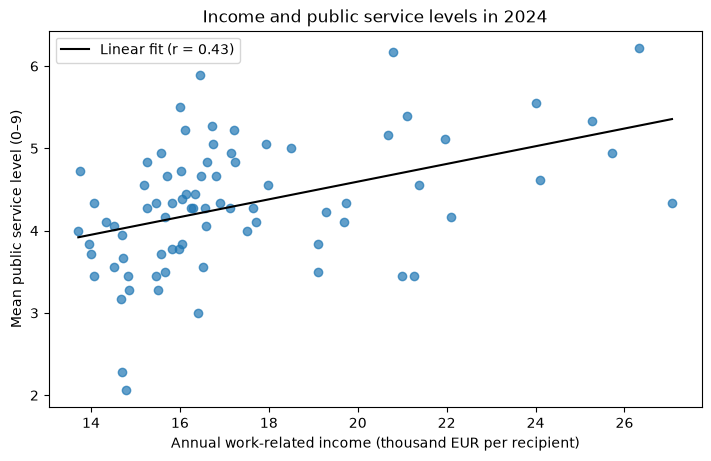

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5), layout="constrained")
ax.scatter(income_thousands, service_mean, alpha=0.7)
grid = np.linspace(income_thousands.min(), income_thousands.max(), 100)
ax.plot(grid, slope * grid + intercept, color="black", label=f"Linear fit (r = {pearson:.2f})")
ax.set(xlabel="Annual work-related income (thousand EUR per recipient)",
       ylabel="Mean public service level (0–9)", title="Income and public service levels in 2024")
ax.legend()
plt.show()

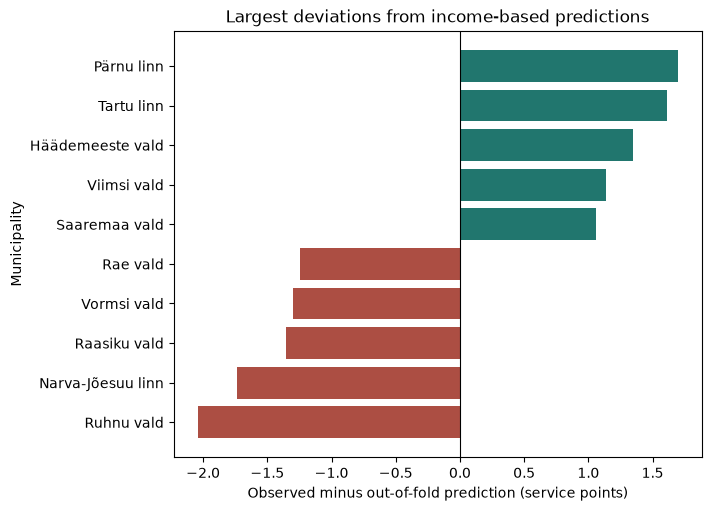

In [10]:
extremes = pd.concat([ordered.head(5), ordered.tail(5)])
fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
ax.barh(extremes["municipality"], extremes["residual"],
        color=np.where(extremes["residual"] > 0, "#21766e", "#ac4e43"))
ax.axvline(0, color="black", linewidth=0.8)
ax.set(xlabel="Observed minus out-of-fold prediction (service points)",
       ylabel="Municipality", title="Largest deviations from income-based predictions")
plt.show()

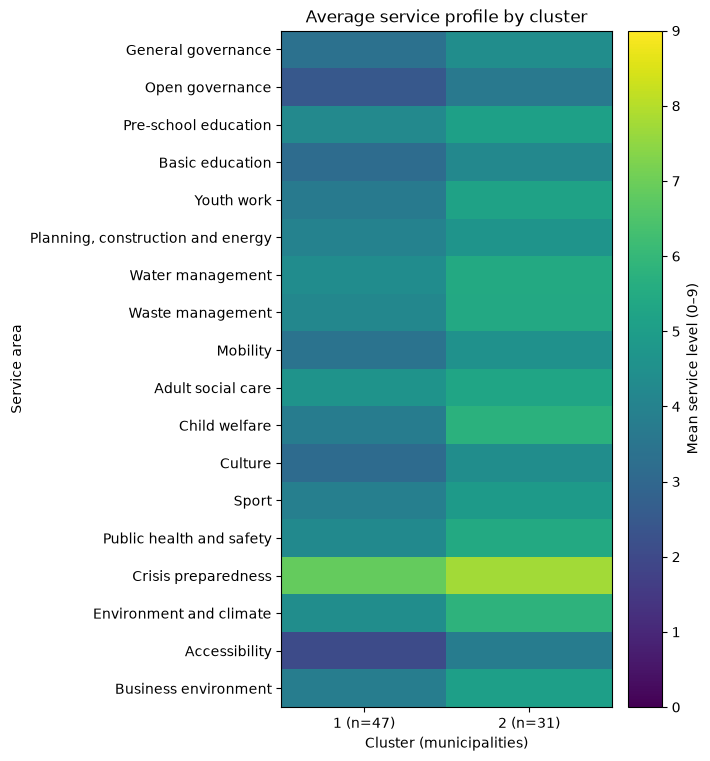

In [11]:
fig, ax = plt.subplots(figsize=(7, 7.5), layout="constrained")
heat = ax.imshow(cluster_means.T, aspect="auto", vmin=0, vmax=9, cmap="viridis")
ax.set_xticks(range(best_k), [f"{i} (n={cluster_sizes[i]})" for i in cluster_means.index])
ax.set_yticks(range(len(service_columns)), service_columns)
ax.set(xlabel="Cluster (municipalities)", ylabel="Service area",
       title="Average service profile by cluster")
fig.colorbar(heat, ax=ax, label="Mean service level (0–9)")
plt.show()

**Answer**

1. The scatter plot shows that municipalities with higher income tend to have higher average service scores (r = 0.43), with a lot of variation.
2. The bar chart shows which municipalities scored furthest above or below the income model’s predictions.
3. The heatmap shows how the average service scores differ between the two groups.

**b. The front page of your repository.**

Write the README: the project name and the authors, the motivation and the goal, what is in which file, and how someone else would repeat your analysis. Paste it here as well.

**Answer**

# D3 — Do wealthier Estonian municipalities have better public services?

Rene Miller, Arthur Klettenberg and Oliver Proos

We examine whether residents’ work-related income is associated with public service levels in Estonia in 2024, identify departures from that relationship and group municipalities by their service profiles.

- `IDS2026_HW10_D3.ipynb` reads and validates the inputs, evaluates the regression and creates the figures.
- `Teenustasemed2024.xlsx` contains the 2024 service ratings. [Minuomavalitsus open data](https://www.minuomavalitsus.ee/avaandmed)
- `UA08_20261126-142152.csv` is the English UA08 export for 2024, with all locations, indicators and income types. [Statistics Estonia UA08](https://andmed.stat.ee/en/stat/eri-valdkondade-statistika__eksperimentaalstatistika__EUROMOD/UA08)

Place both inputs next to the notebook. With Python 3.11 or later, install the dependencies with `python -m pip install jupyter pandas numpy scipy matplotlib openpyxl`. Open the notebook in Jupyter and run **Restart Kernel and Run All Cells** from the notebook directory. If you regenerate the UA08 export, save it under the listed filename. The notebook uses a fixed seed for the cross-validation folds and for clustering.

**c. The last week.**

What is left to do, who does it, and by when? The poster PDF, the project information form, the teamwork description form and access to your code repository are all due on Monday 7 December at 12:00.

**Answer**

- **Oliver, 1 December** — rerun the notebook from the repository and verify that the data download and setup steps work for another team member.
- **Arthur, 2 December** — obtain municipality boundaries, verify the EHAK join and prepare a map of the residuals.
- **Rene, 3 December** — check clustering stability and draft the final interpretation and figure captions.
- **All, 4 December** — review conclusions and figures, check repository access and prepare the project information and teamwork forms. Submit the required final material by **7 December at 12:00 Tallinn time**.

<div style='background-color:#EDF8EF; border-left:4px solid #6EA778; border-radius:6px; padding:12px 16px; margin:16px 0 28px 0; color:#243038;'>

<h2 style="color:#243038; margin:0.2em 0;">Task 4 completion</h2>
<p style="color:#243038; margin:0.5em 0;"><strong>Solved (write only 0 or 1):</strong> 1<br>
<strong>Time spent (voluntary):</strong><br>
<strong>Questions and comments (voluntary):</strong></p>

</div>

<div style='background-color:#FFF6DF; border-top:1px solid #E5CB91; border-left:4px solid #C7952D; border-radius:6px; padding:14px 18px; margin-top:26px; color:#243038;'>

<h2 style="color:#243038; margin:0.2em 0;">Final check</h2>
<p style="color:#243038; margin:0.5em 0;">Before submitting, save and choose <strong>Kernel &gt; Restart &amp; Run All</strong>. Fix unexpected errors and check that all written answers remain visible.</p>

</div>

<div style='background-color:#FFF6DF; border-top:1px solid #E5CB91; border-left:4px solid #C7952D; border-radius:6px; padding:14px 18px; margin-top:26px; color:#243038;'>

<p style="color:#243038; margin:0.4em 0;">Thank you for your effort!</p>

</div>